# HyperImpute: reproduction and limitation tests
The experiments live in `experiments.py` and the settings in `config.py`. Results are cached in `results/`.

In [4]:
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon

import config as cfg
import experiments as ex

sns.set_theme(style="whitegrid")

## 1. Reproduction (MAR 30%, 10 seeds)

In [6]:
main = ex.main_experiment()
ex.table2(main).round(3)

main:   3%|3         | 11/330 [00:00<?, ?it/s]

,dataset,method,paper,paper_std,ours,ours_std,diff_%
0,airfoil,ice_lr,2.349,0.483,1.948,0.496,-17.087
1,airfoil,ice_rf,2.365,0.533,1.906,0.571,-19.407
2,airfoil,ice_cb,2.078,0.482,2.553,0.374,22.844
3,airfoil,hyperimpute,1.479,0.294,1.799,0.532,21.618
4,compression,ice_lr,1.429,0.215,1.491,0.163,4.334
5,compression,ice_rf,1.615,0.141,1.684,0.095,4.288
6,compression,ice_cb,1.251,0.204,2.288,0.159,82.881
7,compression,hyperimpute,1.013,0.145,1.477,0.149,45.799
8,wine_white,ice_lr,0.919,0.060,0.864,0.114,-5.984
9,wine_white,ice_rf,0.987,0.034,0.904,0.125,-8.402


rmse                        wasserstein              \
dataset            airfoil compression wine_white     airfoil compression   
method                                                                      
gain                 0.253       0.211      0.103       0.124       0.161   
hyperimpute          0.180       0.148      0.079       0.079       0.081   
hyperimpute_naive    0.136       0.115      0.079       0.031       0.040   
ice_cb               0.255       0.229      0.110       0.186       0.280   
ice_lr               0.195       0.149      0.086       0.081       0.091   
ice_rf               0.191       0.168      0.090       0.100       0.160   
mean                 0.256       0.230      0.110       0.187       0.282   
miwae                0.286       0.252      0.114       0.102       0.177   
sklearn_ice          0.199       0.157      0.086       0.084       0.090   
sklearn_missforest   0.190       0.175      0.091       0.087       0.117   
softimpute           0.300       0.271      0.107       0.124       0.171   

                               
dataset            wine_white  
method                         
gain                    0.076  
hyperimpute             0.032  
hyperimpute_naive       0.032  
ice_cb                  0.120  
ice_lr                  0.051  
ice_rf                  0.072  
mean                    0.120  
miwae                   0.063  
sklearn_ice             0.041  
sklearn_missforest      0.056  
softimpute              0.060

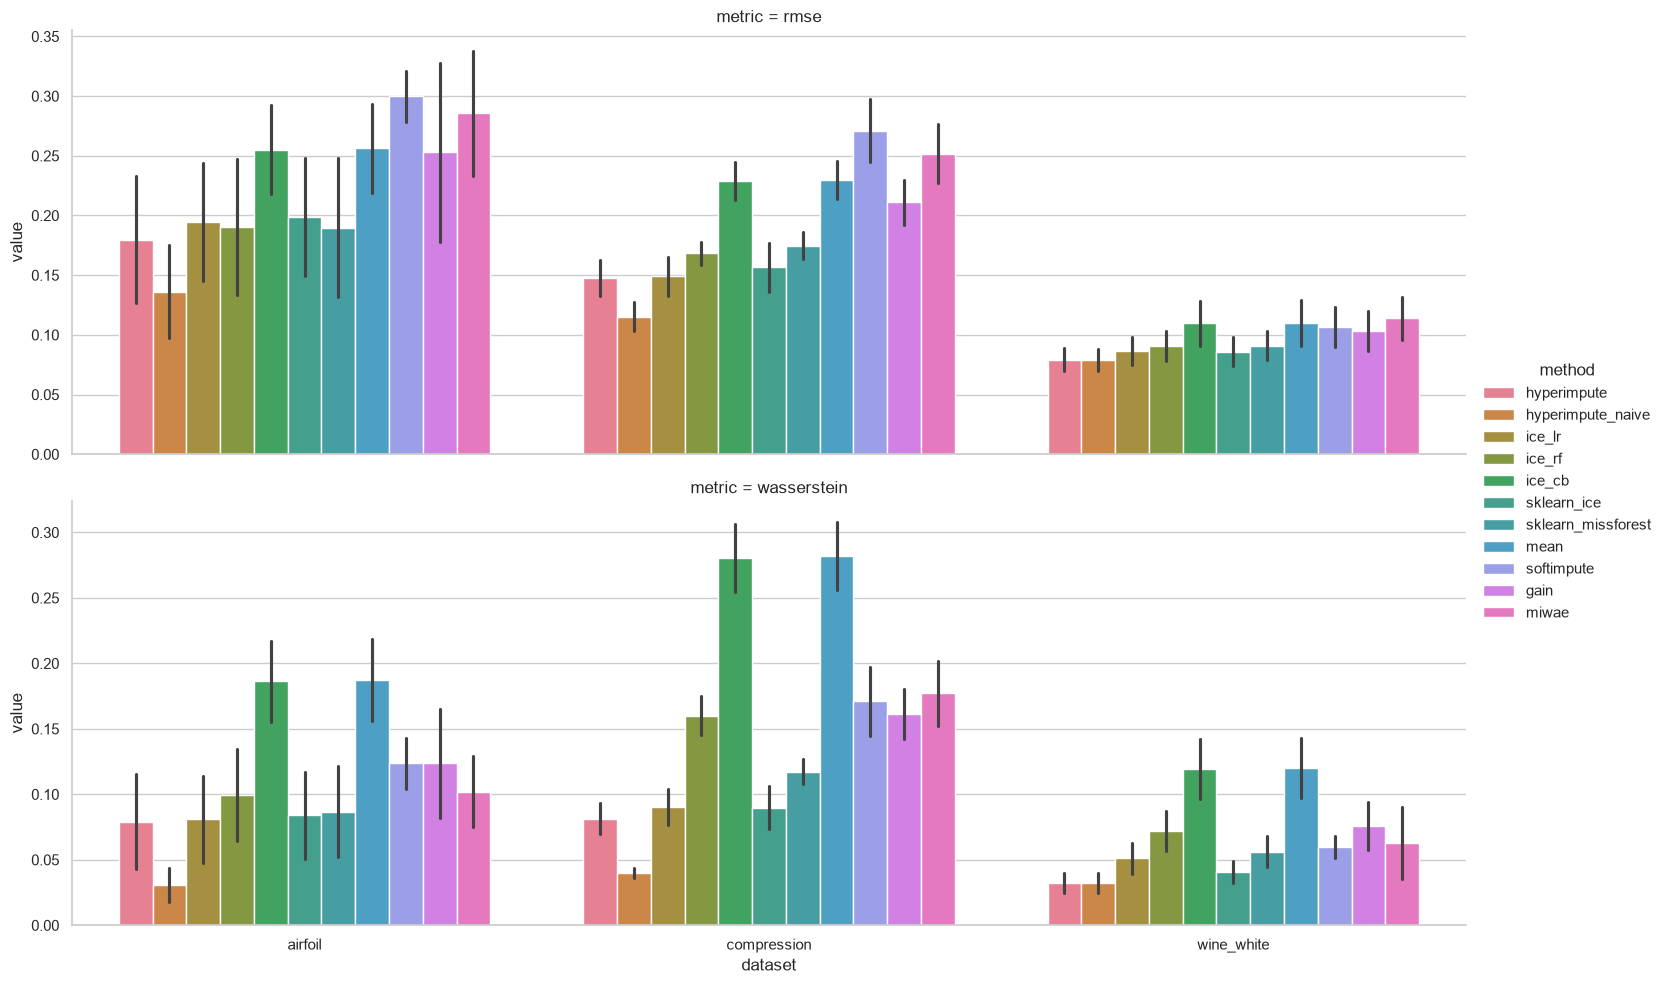

In [7]:
long = main.melt(["dataset", "method"], ["rmse", "wasserstein"], "metric")
sns.catplot(long, x="dataset", y="value", hue="method", row="metric",
            kind="bar", errorbar="sd", sharey=False, aspect=3)
main.pivot_table(["rmse", "wasserstein"], "method", "dataset").round(3)

## 2. Limitation tests

### Test 1: hyperparameter tuning vs model choice

airfoil p = 0.0098
compression p = 0.002
wine_white p = 0.8457


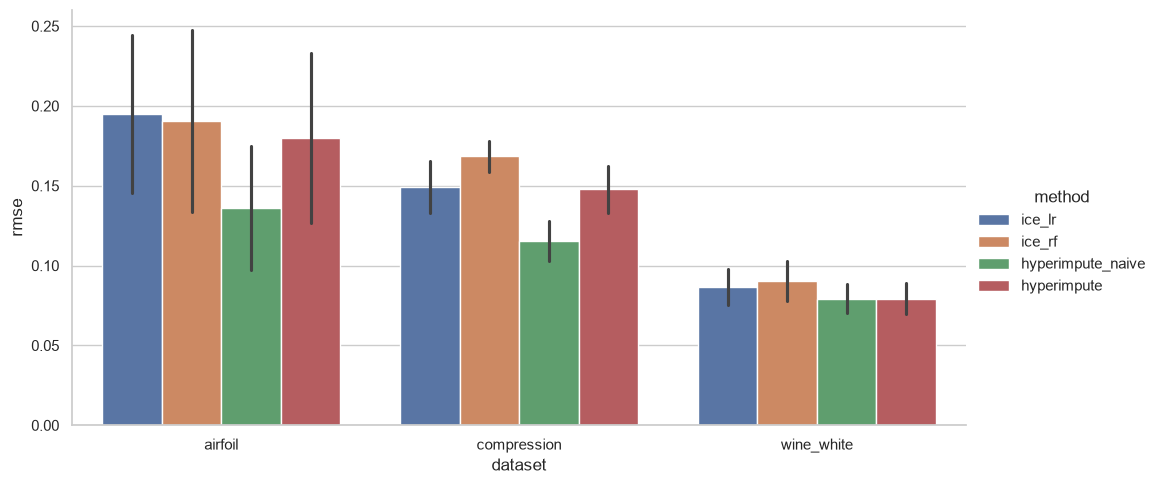

In [8]:
methods = ["ice_lr", "ice_rf", "hyperimpute_naive", "hyperimpute"]
sns.catplot(main, x="dataset", y="rmse", hue="method", hue_order=methods,
            kind="bar", errorbar="sd", aspect=2)

# Wilcoxon test: does tuning hyperimpute beat model choice alone hyperimpute_naive?
rmse = main.pivot_table("rmse", ["dataset", "seed"], "method")
for dataset in cfg.DATASETS:
    p = wilcoxon(rmse.loc[dataset].hyperimpute, rmse.loc[dataset].hyperimpute_naive).pvalue
    print(dataset, "p =", round(p, 4))

### Test 2: runtime vs accuracy

dataset,airfoil,compression,wine_white
method,,,
gain,10.8,6.1,8.3
hyperimpute,289.5,453.5,109.6
hyperimpute_naive,31.6,24.9,32.1
ice_cb,3.0,3.1,3.5
ice_lr,0.4,0.4,0.4
ice_rf,8.1,7.7,9.5
mean,0.0,0.0,0.0
miwae,53.0,24.5,139.8
sklearn_ice,0.3,1.3,1.8


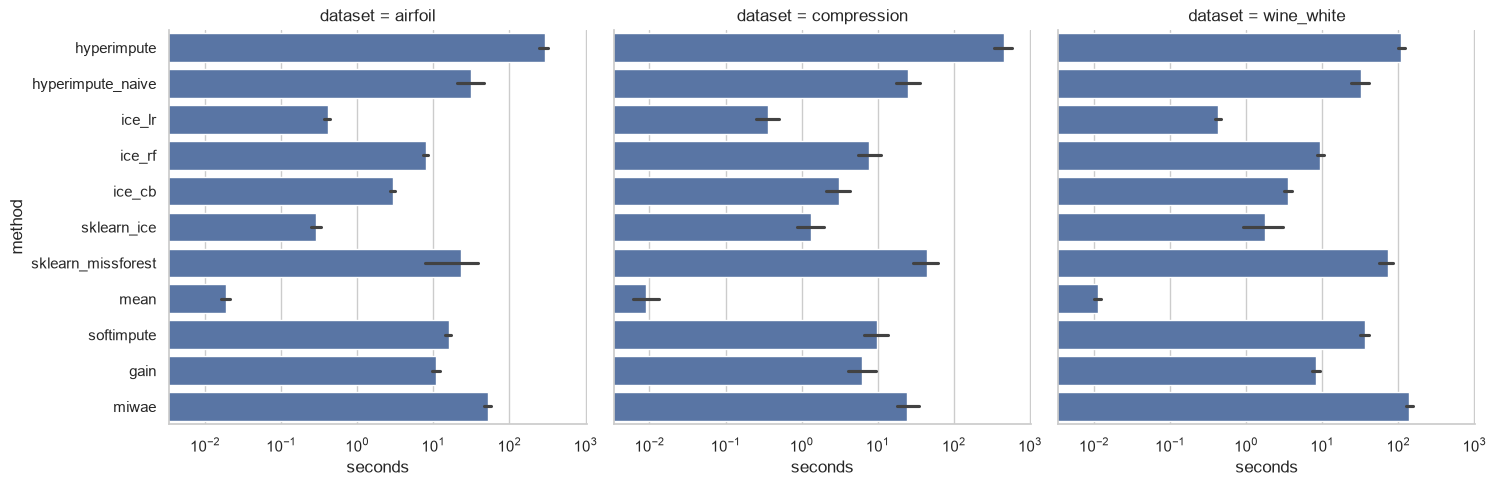

In [9]:
grid = sns.catplot(main, x="seconds", y="method", col="dataset", kind="bar")
grid.set(xscale="log")
main.pivot_table("seconds", "method", "dataset").round(1)

### Test 3: MCAR vs MAR vs MNAR

mechanisms:   0%|          | 0/45 [00:00<?, ?it/s]

mechanism                         MAR   MCAR   MNAR
dataset     method                                 
airfoil     hyperimpute_naive   0.163  0.185  0.196
            mean                0.268  0.273  0.276
            sklearn_ice         0.208  0.246  0.249
            sklearn_missforest  0.201  0.232  0.228
compression hyperimpute_naive   0.115  0.138  0.140
            mean                0.228  0.222  0.221
            sklearn_ice         0.158  0.172  0.176
            sklearn_missforest  0.179  0.184  0.189
wine_white  hyperimpute_naive   0.076  0.081  0.082
            mean                0.105  0.105  0.106
            sklearn_ice         0.082  0.096  0.095
            sklearn_missforest  0.087  0.091  0.091

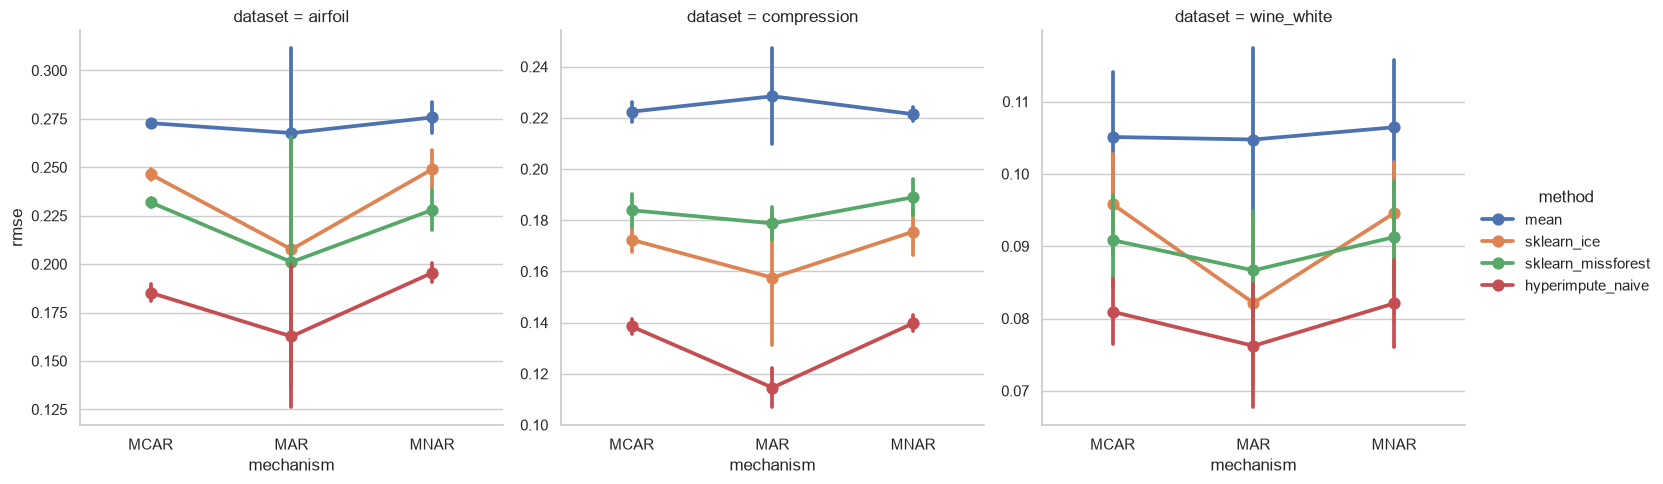

In [10]:
mechanisms = ex.mechanism_experiment()
sns.catplot(mechanisms, x="mechanism", y="rmse", hue="method", col="dataset",
            kind="point", order=cfg.MECHANISMS, errorbar="sd", sharey=False)
mechanisms.pivot_table("rmse", ["dataset", "method"], "mechanism").round(3)

### Test 4: few features

features:   0%|          | 0/30 [00:00<?, ?it/s]

method,hyperimpute_naive,sklearn_ice,sklearn_missforest
n_features,,,
2,0.112,0.114,0.112
3,0.109,0.098,0.101
4,0.115,0.113,0.113
6,0.112,0.124,0.112
8,0.089,0.092,0.093
12,0.069,0.073,0.078


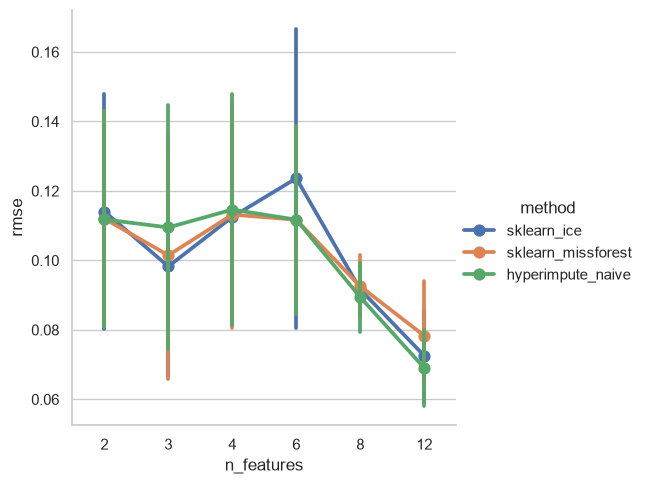

In [11]:
features = ex.feature_experiment()
sns.catplot(features, x="n_features", y="rmse", hue="method", kind="point", errorbar="sd")
features.pivot_table("rmse", "n_features", "method").round(3)

### Test 5: single imputation shrinks the spread

dataset,airfoil,compression,wine_white
method,,,
gain,0.44,0.47,0.41
hyperimpute,0.71,0.78,0.75
hyperimpute_naive,0.91,0.92,0.75
ice_cb,0.01,0.01,0.00
ice_lr,0.67,0.73,0.58
ice_rf,0.52,0.46,0.39
mean,0.00,0.00,0.00
miwae,0.64,0.47,0.52
sklearn_ice,0.74,0.84,0.69


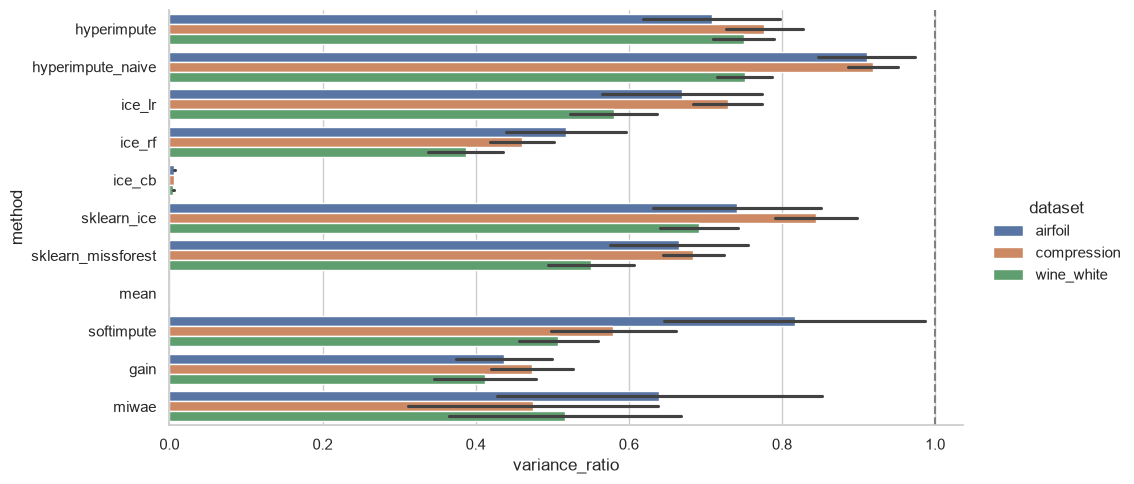

In [12]:
grid = sns.catplot(main, x="variance_ratio", y="method", hue="dataset",
                   kind="bar", errorbar="sd", aspect=2)
grid.refline(x=1)  # 1 = imputed values are as spread out as the true ones
main.pivot_table("variance_ratio", "method", "dataset").round(2)

true                  0.133
hyperimpute_naive     0.074
sklearn_missforest    0.033
dtype: float64

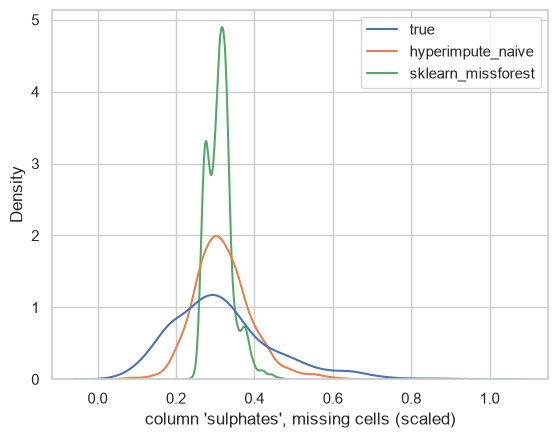

In [13]:
column, values = ex.density_example()
values = pd.DataFrame(values)
sns.kdeplot(values).set_xlabel(f"column '{column}', missing cells (scaled)")
values.std().round(3)

## Findings
_FILL_